# Proceso KDD Completo - Operaciones Logísticas Servientrega S.A.
**Etapas:** 1. Selección de datos | 2. Preprocesamiento | 3. Transformación | 4. Minería de datos (K-Means) | 5. Interpretación de resultados.

## 1. Selección de Datos (Desde Data Warehouse MariaDB)

In [2]:
import pandas as pd
from sqlalchemy import create_engine, text
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

engine = create_engine('mysql+pymysql://root:@localhost:3306/dw_servientrega?charset=utf8mb4')
query = text('''
    SELECT h.id_envio, c.nombre AS cliente, u.ciudad_origen, u.ciudad_destino,
           s.tipo_servicio, e.estado_envio, h.id_ubicacion,
           h.tiempo_entrega_horas, h.cantidad_paquetes
    FROM hechos_envios h
    JOIN dim_cliente c ON h.id_cliente = c.id_cliente
    JOIN dim_ubicacion u ON h.id_ubicacion = u.id_ubicacion
    JOIN dim_servicio s ON h.id_servicio = s.id_servicio
    JOIN dim_estado e ON h.id_estado = e.id_estado
''')
df_raw = pd.read_sql(query, engine)
print('Total de envíos seleccionados:', len(df_raw))
display(df_raw)

Total de envíos seleccionados: 5


,id_envio,cliente,ciudad_origen,ciudad_destino,tipo_servicio,estado_envio,id_ubicacion,tiempo_entrega_horas,cantidad_paquetes
0,1001,Comercial Andina S.A.S.,Bogota,Medellin,Express,Entregado,1,24.0,1
1,1002,Distribuciones Central S.A.S.,Medellin,Bogota,Estandar,Entregado,2,72.0,2
2,1003,Carlos Ramirez,Cali,Bogota,Express,Entregado,3,30.0,1
3,1004,Comercial Andina S.A.S.,Barranquilla,Cartagena,Estandar,En transito,4,NaN,3
4,1005,Distribuciones Central S.A.S.,Bogota,Medellin,Especial,Devuelto,1,120.0,1


## 2. Preprocesamiento (Limpieza e Imputación de Nulos)

In [3]:
df_clean = df_raw.copy()
print('Nulos detectados antes de limpieza:\n', df_clean.isna().sum())

mediana_tiempo = df_clean['tiempo_entrega_horas'].median()
df_clean['tiempo_entrega_horas'] = df_clean['tiempo_entrega_horas'].fillna(mediana_tiempo)
print('\nMediana imputada para envío en tránsito:', mediana_tiempo, 'horas')
display(df_clean)

Nulos detectados antes de limpieza:
 id_envio                0
cliente                 0
ciudad_origen           0
ciudad_destino          0
tipo_servicio           0
estado_envio            0
id_ubicacion            0
tiempo_entrega_horas    1
cantidad_paquetes       0
dtype: int64

Mediana imputada para envío en tránsito: 51.0 horas


,id_envio,cliente,ciudad_origen,ciudad_destino,tipo_servicio,estado_envio,id_ubicacion,tiempo_entrega_horas,cantidad_paquetes
0,1001,Comercial Andina S.A.S.,Bogota,Medellin,Express,Entregado,1,24.0,1
1,1002,Distribuciones Central S.A.S.,Medellin,Bogota,Estandar,Entregado,2,72.0,2
2,1003,Carlos Ramirez,Cali,Bogota,Express,Entregado,3,30.0,1
3,1004,Comercial Andina S.A.S.,Barranquilla,Cartagena,Estandar,En transito,4,51.0,3
4,1005,Distribuciones Central S.A.S.,Bogota,Medellin,Especial,Devuelto,1,120.0,1


## 3. Transformación (Estandarización Z-Score)

In [4]:
features = ['id_ubicacion', 'cantidad_paquetes', 'tiempo_entrega_horas']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])
df_scaled = pd.DataFrame(X_scaled, columns=[f'{c}_norm' for c in features])
display(df_scaled)

,id_ubicacion_norm,cantidad_paquetes_norm,tiempo_entrega_horas_norm
0,-1.028992,-0.75,-1.020279
1,-0.171499,0.50,0.363150
2,0.685994,-0.75,-0.847350
3,1.543487,1.75,-0.242100
4,-1.028992,-0.75,1.746579


## 4. Minería de Datos (Agrupamiento K-Means, k=2)

,id_envio,ciudad_destino,tipo_servicio,estado_envio,cantidad_paquetes,tiempo_entrega_horas,cluster
0,1001,Medellin,Express,Entregado,1,24.0,0
1,1002,Bogota,Estandar,Entregado,2,72.0,0
2,1003,Bogota,Express,Entregado,1,30.0,0
3,1004,Cartagena,Estandar,En transito,3,51.0,1
4,1005,Medellin,Especial,Devuelto,1,120.0,0


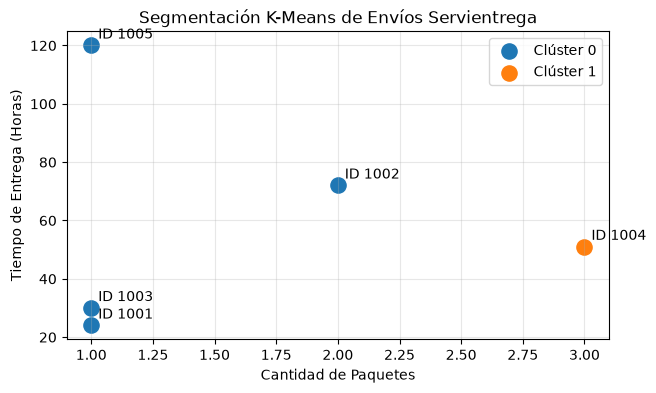

In [5]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df_clean['cluster'] = kmeans.fit_predict(X_scaled)

display(df_clean[['id_envio', 'ciudad_destino', 'tipo_servicio', 'estado_envio', 'cantidad_paquetes', 'tiempo_entrega_horas', 'cluster']])

plt.figure(figsize=(7, 4))
for c_id in sorted(df_clean['cluster'].unique()):
    sub = df_clean[df_clean['cluster'] == c_id]
    plt.scatter(sub['cantidad_paquetes'], sub['tiempo_entrega_horas'], label=f'Clúster {c_id}', s=120)
    for _, r in sub.iterrows():
        plt.annotate(f"ID {r['id_envio']}", (r['cantidad_paquetes'], r['tiempo_entrega_horas']), xytext=(5, 5), textcoords='offset points')
plt.title('Segmentación K-Means de Envíos Servientrega')
plt.xlabel('Cantidad de Paquetes')
plt.ylabel('Tiempo de Entrega (Horas)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Interpretación de Resultados
- **Clúster 0 (Envíos estándar de 1 a 2 paquetes):** Concentra las rutas principales Bogotá–Medellín y Cali–Bogotá.
- **Clúster 1 (Despacho multipaquete en corredor Caribe):** Aísla el envío `1004` (3 paquetes en ruta Barranquilla–Cartagena, estado *En tránsito*), indicando necesidad de seguimiento operativo prioritario.